In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Person B - Ames Housing Analysis")
print("Everything works!")


Person B - Ames Housing Analysis
Everything works!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

housing = pd.read_csv("data/AmesHousing.csv", sep="\t")

print(housing.head())

   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condition  SalePrice  
0       

In [5]:
print("Number of rows:", housing.shape[0])
print("Number of columns:", housing.shape[1])

print("\nColumn names:")
print(housing.columns.tolist())

Number of rows: 2930
Number of columns: 82

Column names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area'

In [6]:

# Selectam doar coloanele numerice
numeric_data = housing.select_dtypes(include="number")

# Calculam matricea de corelatie
correlation_matrix = numeric_data.corr()

# Afisam corelatiile cu pretul casei
price_correlations = correlation_matrix["SalePrice"].sort_values(
    ascending=False
)

print(price_correlations)


SalePrice          1.000000
Overall Qual       0.799262
Gr Liv Area        0.706780
Garage Cars        0.647877
Garage Area        0.640401
Total Bsmt SF      0.632280
1st Flr SF         0.621676
Year Built         0.558426
Full Bath          0.545604
Year Remod/Add     0.532974
Garage Yr Blt      0.526965
Mas Vnr Area       0.508285
TotRms AbvGrd      0.495474
Fireplaces         0.474558
BsmtFin SF 1       0.432914
Lot Frontage       0.357318
Wood Deck SF       0.327143
Open Porch SF      0.312951
Half Bath          0.285056
Bsmt Full Bath     0.276050
2nd Flr SF         0.269373
Lot Area           0.266549
Bsmt Unf SF        0.182855
Bedroom AbvGr      0.143913
Screen Porch       0.112151
Pool Area          0.068403
Mo Sold            0.035259
3Ssn Porch         0.032225
BsmtFin SF 2       0.005891
Misc Val          -0.015691
Yr Sold           -0.030569
Order             -0.031408
Bsmt Half Bath    -0.035835
Low Qual Fin SF   -0.037660
MS SubClass       -0.085092
Overall Cond      -0

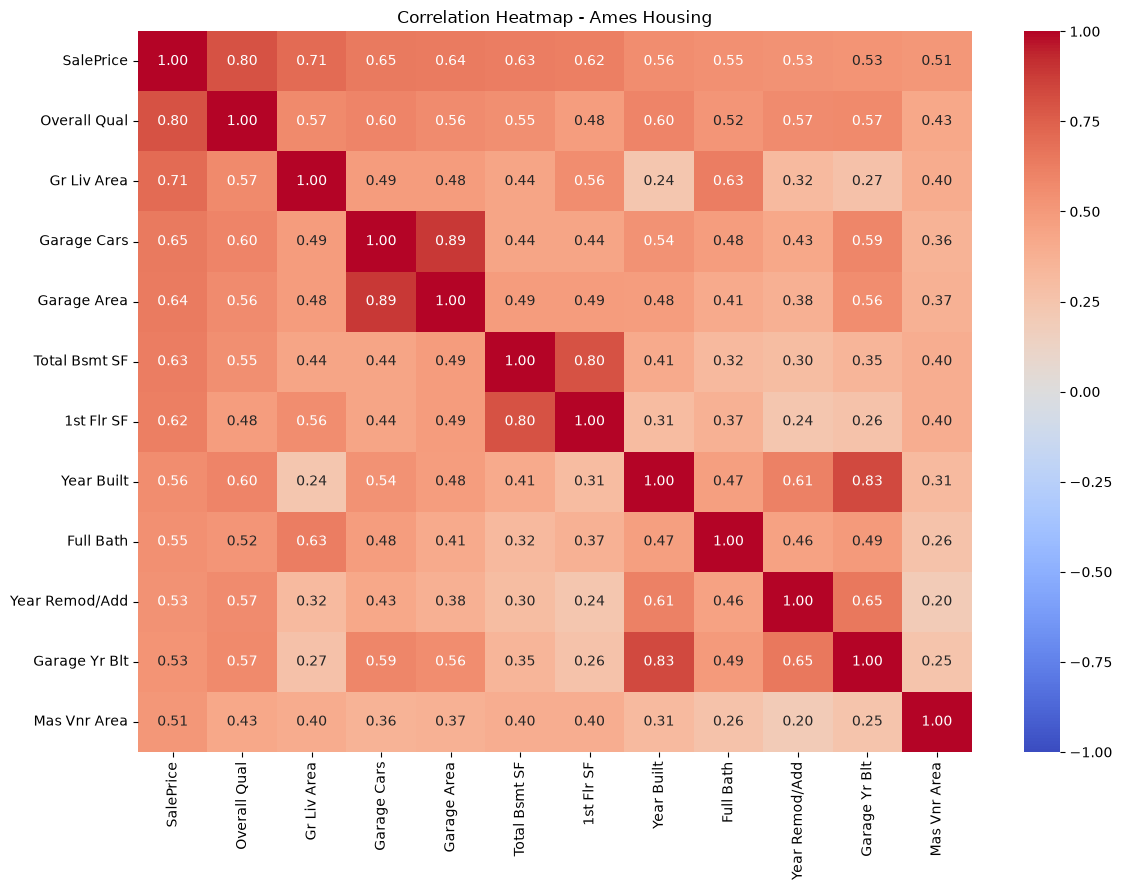

In [7]:

# Selectam cele mai importante 12 variabile
top_features = (
    correlation_matrix["SalePrice"]
    .abs()
    .sort_values(ascending=False)
    .head(12)
    .index
)

# Cream heatmap-ul
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix.loc[top_features, top_features],
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Ames Housing")
plt.tight_layout()
plt.show()


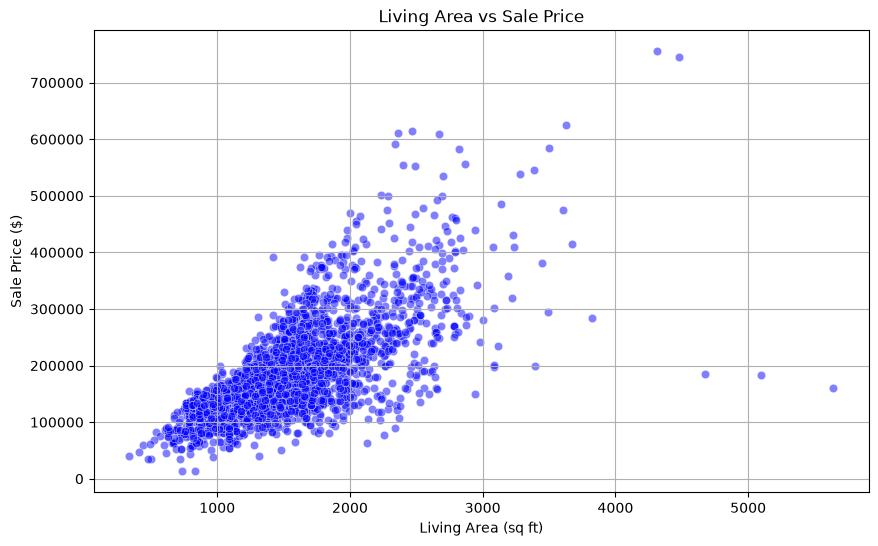

In [8]:

# Graficul 1: Living Area vs Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=housing,
    x="Gr Liv Area",
    y="SalePrice",
    alpha=0.5,
    color="blue"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.grid(True)

plt.show()


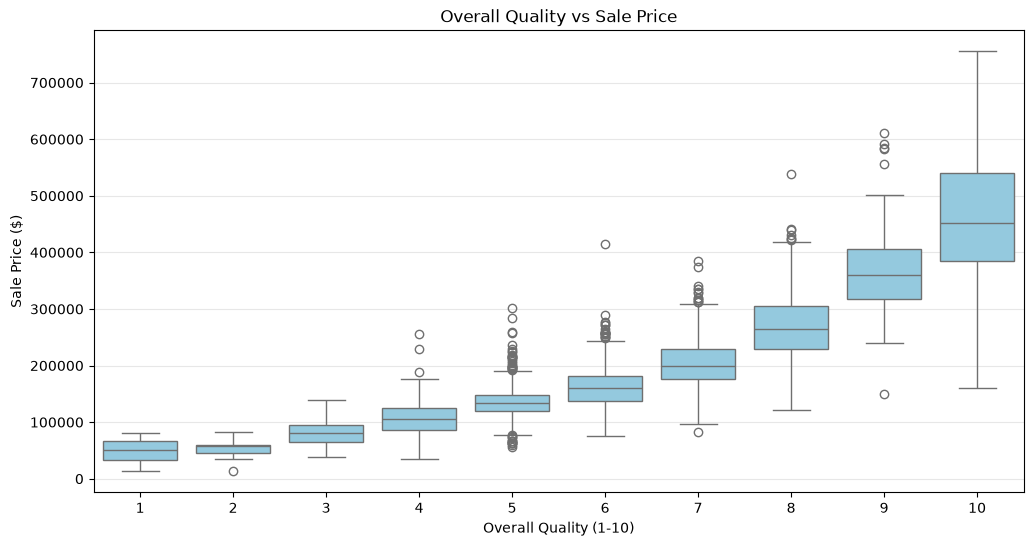

In [9]:

# Graficul 2: Overall Quality vs Sale Price

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=housing,
    x="Overall Qual",
    y="SalePrice",
    color="skyblue"
)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("Sale Price ($)")
plt.grid(axis="y", alpha=0.3)

plt.show()


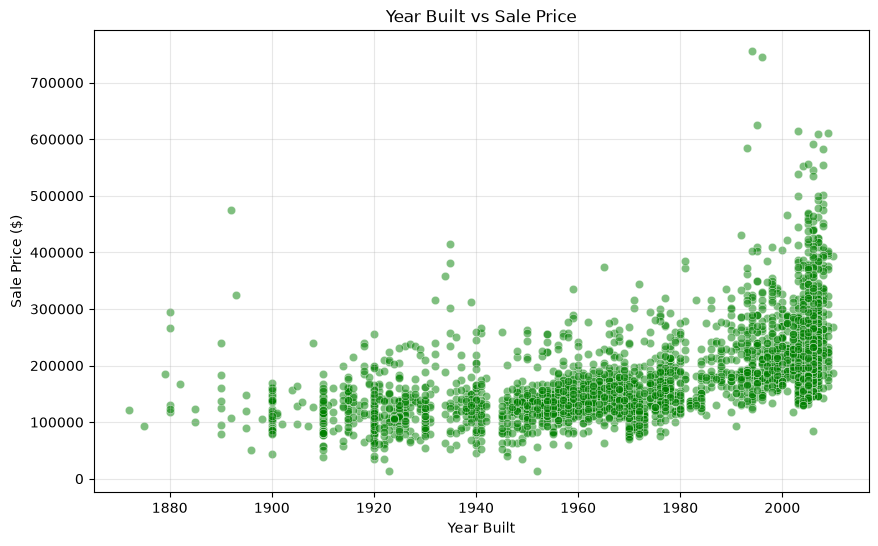

In [10]:

# Graficul 3: Year Built vs Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=housing,
    x="Year Built",
    y="SalePrice",
    alpha=0.5,
    color="green"
)

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price ($)")
plt.grid(True, alpha=0.3)

plt.show()


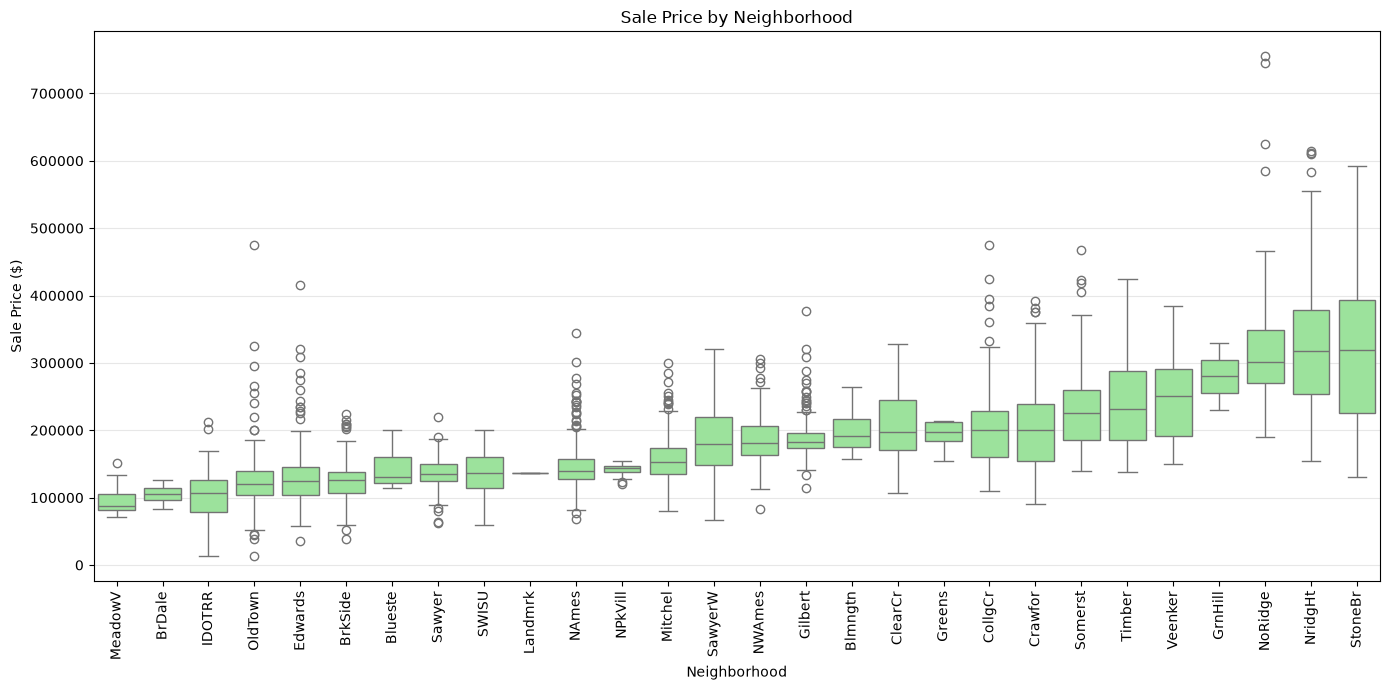

In [11]:

# Graficul 4: Neighborhood vs Sale Price

# Ordonam cartierele dupa pretul median
neighborhood_order = (
    housing.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=housing,
    x="Neighborhood",
    y="SalePrice",
    order=neighborhood_order,
    color="lightgreen"
)

plt.title("Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price ($)")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


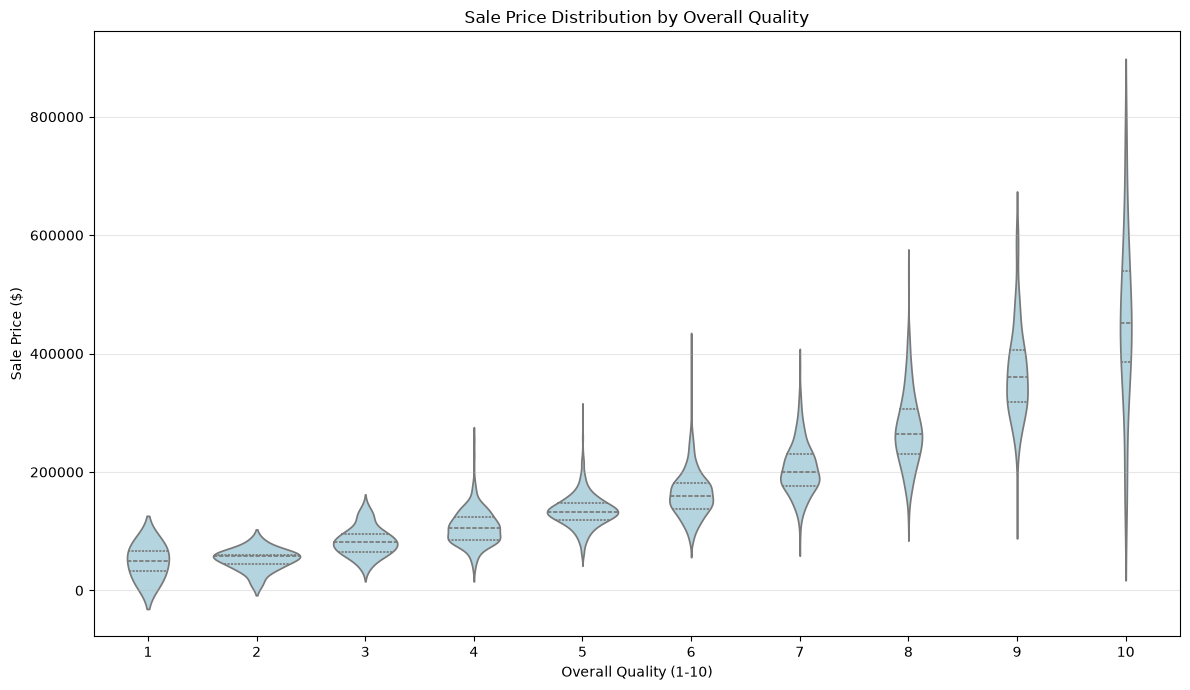

In [12]:

# Graficul 5: Violin Plot - Overall Quality vs Sale Price

plt.figure(figsize=(12, 7))

sns.violinplot(
    data=housing,
    x="Overall Qual",
    y="SalePrice",
    color="lightblue",
    inner="quartile"
)

plt.title("Sale Price Distribution by Overall Quality")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("Sale Price ($)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


In [13]:

# FEATURE ENGINEERING - PERSON B

# 1. Total Area
housing["TotalArea"] = (
    housing["Gr Liv Area"] +
    housing["Total Bsmt SF"]
)

# 2. House Age
housing["HouseAge"] = (
    housing["Yr Sold"] -
    housing["Year Built"]
)

# 3. Years Since Last Remodel
housing["YearsSinceRemodel"] = (
    housing["Yr Sold"] -
    housing["Year Remod/Add"]
)

# Display the new features
print(
    housing[
        ["TotalArea", "HouseAge",
         "YearsSinceRemodel", "SalePrice"]
    ].head()
)


   TotalArea  HouseAge  YearsSinceRemodel  SalePrice
0     2736.0        50                 50     215000
1     1778.0        49                 49     105000
2     2658.0        52                 52     172000
3     4220.0        42                 42     244000
4     2557.0        13                 12     189900


In [14]:

# Correlation of new features with SalePrice

new_features = [
    "TotalArea",
    "HouseAge",
    "YearsSinceRemodel",
    "SalePrice"
]

print(
    housing[new_features]
    .corr()["SalePrice"]
    .sort_values(ascending=False)
)


SalePrice            1.000000
TotalArea            0.789967
YearsSinceRemodel   -0.534940
HouseAge            -0.558907
Name: SalePrice, dtype: float64


In [15]:

# BONUS - LINEAR REGRESSION
# Living Area vs Sale Price

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

# Select the two features and remove missing values
data = housing[["Gr Liv Area", "SalePrice"]].dropna()

# X = input feature, y = target
X = data[["Gr Liv Area"]]
y = data["SalePrice"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict house prices
y_pred = model.predict(X_test)

# Evaluate the model
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))


R2 Score: 0.523397415369115
Mean Absolute Error: 41365.51131849473


In [16]:

# BONUS - SECOND LINEAR REGRESSION
# Garage Area vs Sale Price

# Select data and remove missing values
garage_data = housing[["Garage Area", "SalePrice"]].dropna()

# Input and target
X_garage = garage_data[["Garage Area"]]
y_garage = garage_data["SalePrice"]

# Split into training and testing data
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_garage,
    y_garage,
    test_size=0.2,
    random_state=42
)

# Create and train the model
garage_model = LinearRegression()
garage_model.fit(X_train_g, y_train_g)

# Predict house prices
garage_pred = garage_model.predict(X_test_g)

# Evaluate the model
print("Garage Area Regression")
print("R2 Score:", r2_score(y_test_g, garage_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test_g, garage_pred))


Garage Area Regression
R2 Score: 0.4315175613928398
Mean Absolute Error: 43902.58821594458


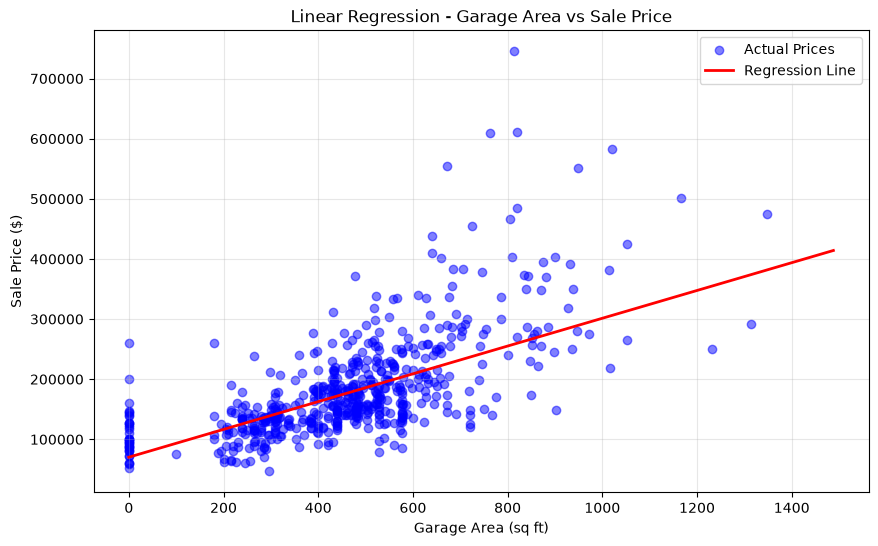

In [17]:

# Garage Area Linear Regression Plot

plt.figure(figsize=(10, 6))

# Actual prices
plt.scatter(
    X_test_g["Garage Area"],
    y_test_g,
    color="blue",
    alpha=0.5,
    label="Actual Prices"
)

# Regression line
x_line_g = np.linspace(
    X_garage["Garage Area"].min(),
    X_garage["Garage Area"].max(),
    100
)

x_line_g_df = pd.DataFrame({
    "Garage Area": x_line_g
})

y_line_g = garage_model.predict(x_line_g_df)

plt.plot(
    x_line_g,
    y_line_g,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Linear Regression - Garage Area vs Sale Price")
plt.xlabel("Garage Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [18]:

# Compare actual and predicted prices

garage_comparison = pd.DataFrame({
    "Actual Price": y_test_g.to_numpy(),
    "Predicted Price": garage_pred
})

garage_comparison["Difference"] = (
    garage_comparison["Actual Price"] -
    garage_comparison["Predicted Price"]
)

print(garage_comparison.head(10).round(2))


   Actual Price  Predicted Price  Difference
0        214000        193225.32    20774.68
1        157000        174281.15   -17281.15
2        260000        169660.62    90339.38
3        183000        166888.31    16111.69
4        120750        141475.40   -20725.40
5         80000        121145.07   -41145.07
6        265900        179363.73    86536.27
7        175500        203390.48   -27890.48
8        144000        203390.48   -59390.48
9        144000        143092.58      907.42


In [19]:

# BONUS - Compare Linear Regression Models

comparison_models = pd.DataFrame({
    "Model": [
        "Living Area vs SalePrice",
        "Garage Area vs SalePrice"
    ],
    "R2 Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test_g, garage_pred)
    ],
    "Mean Absolute Error": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test_g, garage_pred)
    ]
})

print(comparison_models.round(2))


                      Model  R2 Score  Mean Absolute Error
0  Living Area vs SalePrice      0.52             41365.51
1  Garage Area vs SalePrice      0.43             43902.59
